<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/21_QKD_Attack_Detection/QLSTM_QKDAttack_AlKuwari2025.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Hybrid QLSTM for QKD attack detection: Al-Kuwari et al. (2025) step by step

This notebook rebuilds the experiment of one paper from the lecture:

Ali Al-Kuwari, Noureldin Mohamed, Saif Al-Kuwari, Ahmed Farouk, Bikash K. Behera, "Resisting Quantum Key Distribution Attacks Using Quantum Machine Learning", arXiv:2509.14282 (v2, 19 Feb 2026), 2025. https://arxiv.org/abs/2509.14282

**What the paper does.** Quantum key distribution (QKD) lets two parties, Alice and Bob, agree on a secret key using single photons. Real devices are imperfect, so an attacker (Eve) can try tricks such as intercept-and-resend, photon-number splitting, Trojan-horse light injection, random-number-generator tampering and detector blinding. Each attack leaves small traces in the session statistics (error rate, detection rate, timing). The authors (1) simulate a decoy-state BB84 dataset with eight scenarios (normal plus seven attacks, 10,329 sessions), and (2) train a **hybrid quantum LSTM (QLSTM)**, built with PennyLane, to say which scenario a session belongs to. They report 94.7 % accuracy after 50 epochs, above LSTM, CNN, ANN, RNN and Random Forest.

**What this notebook does.** The authors' dataset is only available "upon reasonable request", but the paper describes the simulation in enough detail (Algorithms 2 to 9, Tables III to VI) to **regenerate a dataset of the same kind**. The notebook therefore:

1. simulates the eight QKD scenarios itself (NumPy, every unspecified number marked `# CHOICE`),
2. checks the simulation against the paper's Table VI sample rows and checks the BB84 rule against a PennyLane circuit,
3. builds the hybrid QLSTM (a PennyLane circuit for every gate, QLSTM layer, then classical LSTM with 32 hidden units, then a linear layer),
4. trains it, and ANN / RNN / LSTM / CNN / Random Forest baselines, on identical inputs,
5. re-draws the paper's Table VIII, Figure 3, Figure 4 and Table IX,
6. prints the paper's numbers next to ours with a verdict per claim.

**How to run it.** Open in Google Colab, keep the normal CPU runtime, choose Runtime, then Run all. No GPU and no account are needed. `FAST_MODE = True` (default in the config cell) is a class demo that finishes in about 10 minutes; `FAST_MODE = False` follows the paper's budgets (10,329 sessions, 50 epochs) and takes about one to two hours on a CPU (we measured 125 minutes on a machine shared with four other jobs; the QLSTM training cell dominates).

**What you will get at the end.** Your own measured accuracy, precision, recall, F1 and test loss for every model, confusion matrices, a resource table, and a table that says for every claim of the paper whether it is reproduced, not reached, or cannot be checked on a regenerated dataset.

## 1. The paper in one page

**Problem.** Practical QKD systems leak information through hardware imperfections. Eve can attack the channel or the devices without breaking the physics of BB84. A monitoring system (an intrusion detection system for QKD) should read the session statistics and name the attack.

**Decision.** Multi-class classification of one QKD session (one row of statistics) into 8 classes: Normal, Intercept-and-Resend (called MITM in Table III), PNS, Trojan-Horse, Wavelength-dependent Trojan-Horse, RNG attack, Detector Blinding, Combined attack. Model outputs are said to be "4 logits" in Section II-B3 (Normal, Intercept-and-Resend, PNS, Trojan-Horse), but the dataset, the confusion matrices (Figure 4) and the discussion use all eight classes. This notebook uses **eight**.

**Data.** Simulated decoy-state BB84 (signal pulses 70 %, decoy 30 %), run through the PennyLane library, with three noise sources (channel loss, photon shot noise, depolarising noise) set to low / moderate / high per session. 10,329 samples: 1292 Normal and 1291 of each attack (Table III). Eleven statistics per session (sifted key length, QBER, measurement entropy, signal and decoy detection rate, signal and decoy loss rate, average photon time, whole key time, arrival-time variance, arrival-time deviation); **nine** are used (the two detection rates are dropped because the loss rates carry the same information).

**Preprocessing.** Z-score (StandardScaler), one-hot labels, 80 / 20 train / test split, Gaussian noise (mean 0, std 0.05) added to the training set, batch size 64, sequence length 9 (each of the 9 features is one time step).

**Model.** Hybrid QLSTM: a QLSTM layer (9 qubits, 1 quantum layer, `default.qubit`, Strongly Entangling Layers; four variational circuits for forget, input, candidate and output gates) feeds a classical LSTM with 32 hidden units, then a fully connected layer.

**Training.** CrossEntropyLoss, AdamW (learning rate 0.005 in Table VII, 5e-4 in the text), weight decay 1e-4, cosine annealing with warm restarts (T0 = 50), early stopping (patience 5), 10, 20 and 50 epochs.

**Claims checked here.**
* C1. QLSTM reaches 88.3 % / 93.8 % / 94.7 % accuracy after 10 / 20 / 50 epochs; at 50 epochs precision 95.1 %, F1 94.7 %, test loss 0.189 (Table VIII).
* C2. At 50 epochs QLSTM is more accurate than ANN (92.3 %), LSTM (85.1 %), CNN (84.9 %), Random Forest (82.6 %) and RNN (76.0 %).
* C3. LSTM and CNN peak around 10 to 20 epochs and then degrade, while QLSTM keeps improving.
* C4. Random Forest is a stable baseline near 82 %.
* C5. QLSTM has far fewer classical parameters than the LSTM (3.9e3 + 72 against 4.3e4) and is the slowest per epoch (Table IX).
* C6. Most QLSTM errors are between Normal and PNS (Figure 4).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Dataset | Own simulation, "available upon request" | Re-simulated here from Algorithms 2 to 9; **not the authors' file** (an optional `CSV_PATH` lets you load it if you get it) |
| Samples | 10,329 (1292 Normal + 7 x 1291) | Same counts in full mode; 8 x 250 in `FAST_MODE` |
| Pulses per session | "Ntrans = 50" in Alg. 2 (inconsistent with ~250-bit sifted keys) | **700** pulses sent per session, derived from Table VI (whole key time / average photon time is about 520 detected photons, about 0.73 x 700) |
| Noise strengths | "low, moderate, high" | loss 15 / 25 / 35 %, bit flip 1 / 3 / 6 %, depolarising 0.5 / 2 / 4 %, dark counts 0.2 / 0.8 / 2 % (CHOICE) |
| Attack parameters (p_inject, Eve noise, blinding duration, wavelength offsets, bias strengths, ...) | Named but not given numerically | Chosen once, from the qualitative description in Section III, **not tuned to the accuracy** (CHOICE, see simulator) |
| Measurement entropy | Shannon entropy of match / mismatch | Binary entropy of the QBER (this reproduces the Table VI rows exactly) |
| Detection / loss rate | Table V formulas | Detected pulses / sent pulses per pulse type; loss = 1 - detection |
| Timing per photon | Not specified | Gamma-distributed latency plus attack-specific delays (CHOICE). Table VI shows that the last four scenarios were timed over all 700 pulses and the first four over detected photons only; we copy this (`RECORD_LOST_TIMES`, section 6) |
| Features | 9 of 11 used | Same 9 |
| Sequence input | 9 time steps, one feature each | Same, tensor shape (batch, 9, 1) |
| QLSTM | 9 qubits, 1 q-layer, Strongly Entangling Layers, classical LSTM 32, FC | Same; gate circuit follows the reference implementation (H, RY(arctan x), RZ(arctan x^2), then SEL), hidden size 9 for the QLSTM (it feeds an LSTM with input size 9) |
| Quantum simulation | PennyLane `default.qubit`, GPU | A twin state-vector simulator written in PyTorch (same maths, checked against PennyLane to 1e-12) for speed; PennyLane circuit kept as reference |
| Learning rate | 0.005 (Table VII) and 5e-4 (text) | 0.005 |
| Validation set for early stopping | Not stated (paper reports "test loss") | 10 % of the training set, test set never used for stopping |
| Epochs 10 / 20 / 50 | Separate runs | One 50-epoch run, evaluated at epochs 10, 20, 50 (the schedule T0 = 50 does not depend on the run length) |
| Baseline sizes | Parameter counts in Table IX only | ANN 14k, RNN 10k, CNN 20k, LSTM 41k parameters, chosen to match Table IX |
| Seeds | Not stated, one run | Several seeds for the classical models, one for QLSTM (cost) |

## 2. Install the libraries

Colab already has NumPy, pandas, scikit-learn, matplotlib and PyTorch. We add PennyLane (the paper's framework). The cell does nothing when PennyLane is already installed. If Colab asks you to restart the session after this cell, accept, then run the notebook again from the next cell.

In [1]:
import importlib, subprocess, sys
try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

try:
    import pennylane  # noqa: F401
    HAVE_PL = True
except ImportError:
    HAVE_PL = False

if IN_COLAB or not HAVE_PL:
    # pinned to the version this notebook was tested with
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "pennylane==0.45.1"], check=True)

## 3. Settings

All tunable numbers are in this one cell.

* `FAST_MODE = True` runs a class demo (8 x 250 sessions, 12 epochs, evaluation at epochs 3, 6, 12 which play the role of the paper's 10, 20, 50). `FAST_MODE = False` follows the paper (10,329 sessions, 50 epochs, evaluation at 10, 20, 50).
* `LR = 0.005` is Table VII; the text of the paper says 5e-4 (one of the inconsistencies).
* `N_PULSES = 700` is our choice (see the table above).
* `DATA_SOURCE = "simulate"` regenerates the dataset. Use `"csv"` and `CSV_PATH` if you obtain the authors' file (columns as in Table VI plus `label`).
* `IBM_TOKEN` is unused: the paper only simulates, and so do we.

In [2]:
FAST_MODE = False      # True: ~10 minute class demo. False: the paper's budgets (about 1 to 2 hours on CPU)

SEED = 42
DATA_SOURCE = "simulate"            # "simulate" or "csv"
CSV_PATH = "/content/qkd_dataset.csv"
DATA_DIR = "qkd_data"               # generated data are cached here
IBM_TOKEN = ""                      # not used (no hardware in this paper)

N_PULSES = 700                      # CHOICE: pulses sent per session (derived from Table VI)
RECORD_LOST_TIMES = True            # CHOICE: copy the Table VI bookkeeping (see section 6); False = time detected photons only
TEST_SIZE = 0.20                    # paper: 80 / 20 split
VAL_FRAC = 0.10                     # CHOICE: part of the training set kept for early stopping
NOISE_STD = 0.05                    # paper: Gaussian noise on the training set
BATCH = 64
LR = 0.005                          # Table VII (text says 5e-4)
WEIGHT_DECAY = 1e-4
PATIENCE = 5
N_QUBITS = 9
LSTM_HIDDEN = 32
QUANTUM_BACKEND = "torch"           # "torch" (fast twin simulator) or "pennylane" (exact reference, ~20x slower)

if FAST_MODE:
    N_PER_CLASS = 250
    MAX_EPOCHS = 12
    SNAPSHOTS = (3, 6, 12)           # stand-ins for the paper's 10 / 20 / 50 epochs
    CLASSICAL_SEEDS = [42, 43, 44]
    QLSTM_SEEDS = [42]
    RF_TREES = [500]
else:
    N_PER_CLASS = 1291
    MAX_EPOCHS = 50
    SNAPSHOTS = (10, 20, 50)
    CLASSICAL_SEEDS = [42, 43, 44, 45, 46]
    QLSTM_SEEDS = [42, 43]           # two runs: one QLSTM epoch costs about a minute on a CPU
    RF_TREES = [500, 1000, 10000]

## 4. Imports and seeds

In [3]:
import os, time, math, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn
import pennylane as qml
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, confusion_matrix,
                             log_loss, f1_score)

warnings.filterwarnings("ignore")
os.makedirs(DATA_DIR, exist_ok=True)
torch.set_num_threads(max(1, min(4, os.cpu_count() or 1)))

def seed_all(seed):
    np.random.seed(seed)
    torch.manual_seed(seed)

seed_all(SEED)
rng_global = np.random.default_rng(SEED)
print("numpy", np.__version__, "| torch", torch.__version__, "| pennylane", qml.__version__, "| sklearn", sklearn.__version__)

numpy 2.5.4 | torch 2.14.1+cpu | pennylane 0.45.1 | sklearn 1.9.1


## 5. The QKD simulator (decoy-state BB84 with seven attacks)

### BB84 in two minutes

Alice sends photons, each carrying a random bit in a random basis (rectilinear or diagonal). Bob measures each photon in a random basis. If Bob's basis equals Alice's, he gets her bit (up to noise). If the bases differ, his result is a coin flip. They publicly compare bases and keep only the matching positions (the **sifted key**, about half of the detected photons). The **QBER** is the fraction of sifted positions where Bob's bit differs from Alice's. Without Eve it equals the device noise; with intercept-and-resend Eve it rises by up to 25 points.

**Decoy states.** Alice mixes in decoy pulses with another intensity so that a photon-number-splitting attacker is exposed by the different detection rates of signal and decoy pulses. The paper uses 70 % signal and 30 % decoy.

### What each session produces

One row of the dataset is one **session** of `N_PULSES` pulses. From it we compute the paper's Table V quantities: sifted key length, QBER, measurement entropy, signal and decoy detection / loss rates, mean, total, variance and mean absolute deviation of the photon arrival times.

### How each attack is modelled (Algorithms 3 to 9)

| Scenario | Mechanism in the code |
|---|---|
| Normal | loss, bit flips, depolarisation, dark counts, random latency |
| Intercept-and-Resend | Eve measures a fraction of pulses in a random basis, her measurement is noisy, she resends; extra loss and extra delay on intercepted pulses |
| PNS | 20 % of pulses are multi-photon (Alg. 4); on those Eve removes a photon, which costs extra loss and a small delay; no extra bit errors |
| Trojan-horse | injection with probability `p_inject`; strong probes (50 %) raise Bob's detection probability and flip the result with probability 0.5, weak probes use 0.6 detection and flip 0.2 (Alg. 5) |
| Wavelength-dependent Trojan-horse | injected pulses at offsets of 5 to 40 nm lose efficiency `exp(-d/60)`, get a phase-error probability and a wavelength-dependent delay (Alg. 6) |
| RNG | Alice's bit and both bases are biased; Eve predicts bases from the bias and intercepts only when she predicts well (Alg. 7); larger key length because biased bases coincide more often |
| Detector blinding | bursts of `d_blind` pulses in which Bob's detectors only click for Eve's trigger pulses (Alg. 8); lower detection rate, extra errors when Eve's basis differs from Alice's |
| Combined | wavelength + RNG + blinding mechanisms together, each active on a random half of the pulses (Alg. 9) |

Every numeric parameter is drawn per session from a range marked `# CHOICE` in the code. The ranges were written from the qualitative text of Section III **before** any model was trained and were not adjusted to the accuracy.

In [4]:
import numpy as np
import pandas as pd

SCENARIOS = ["normal", "mitm attack", "pns attack", "trojan horse attack",
             "wavelength dependent trojan attack", "rng attack",
             "detector blinding attack", "combined attack"]

FEATURES_ALL = ["sifted_key_length", "qber", "measurement_entropy", "signal_detection_rate",
                "decoy_detection_rate", "signal_loss_rate", "decoy_loss_rate",
                "avg_photon_time", "whole_key_time", "arrival_var", "arrival_dev"]
FEATURES_USED = [f for f in FEATURES_ALL if f not in ("signal_detection_rate", "decoy_detection_rate")]


def h2(p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return -(p * np.log2(p) + (1 - p) * np.log2(1 - p))


ARTIFACT_SCENARIOS = ("wavelength dependent trojan attack", "rng attack", "detector blinding attack", "combined attack")


def simulate_scenario(scenario, S, N, rng, record_lost_times=True):
    """Vectorised decoy-state BB84 simulation: S sessions x N pulses (one row = one dataset sample)."""
    sh = (S, N)
    col = lambda x: x[:, None]
    U = lambda lo, hi: col(rng.uniform(lo, hi, S))
    # ---- session environment: noise strength low / moderate / high (paper: "set to low, moderate, or high")
    lvl = rng.integers(0, 3, S)
    loss = col(np.array([0.15, 0.25, 0.35])[lvl]) + U(-0.03, 0.03)          # CHOICE channel loss prob
    p_err = col(np.array([0.010, 0.030, 0.060])[rng.integers(0, 3, S)])     # CHOICE bit-flip prob
    p_dep = col(np.array([0.005, 0.020, 0.040])[rng.integers(0, 3, S)])     # CHOICE depolarisation prob
    p_dark = col(np.array([0.002, 0.008, 0.020])[rng.integers(0, 3, S)])    # CHOICE shot/dark-count click prob
    lat_mean = U(0.055, 0.085)                                              # CHOICE base photon latency
    lat_shape = 2.4

    is_sig = rng.random(sh) < 0.7                                           # p_sig = 0.7 (Alg. 2)
    a = rng.random(sh) < 0.5
    flags = dict(ir=scenario == "mitm attack", pns=scenario == "pns attack",
                 tha=scenario == "trojan horse attack", wl=scenario in ("wavelength dependent trojan attack", "combined attack"),
                 rng=scenario in ("rng attack", "combined attack"), blind=scenario in ("detector blinding attack", "combined attack"))
    comb = scenario == "combined attack"
    act = lambda: (rng.random(sh) < 0.5) if comb else np.ones(sh, bool)     # CHOICE combined: each attack active w.p. 0.5 per pulse

    # bases (biased RNG for Alice and Bob under RNG attack)
    if flags["rng"]:
        b_bit = U(0.60, 0.85); b_basis = U(0.60, 0.85)                       # CHOICE bias strengths
        rng_on = act()
        a = np.where(rng_on, rng.random(sh) < b_bit, a)
        bA = np.where(rng_on, rng.random(sh) < b_basis, rng.random(sh) < 0.5)
        bB = np.where(rng_on, rng.random(sh) < b_basis, rng.random(sh) < 0.5)
    else:
        bA = rng.random(sh) < 0.5
        bB = rng.random(sh) < 0.5

    # state travelling on the channel: bit s, basis sb
    s, sb = a.copy(), bA.copy()
    extra_loss = np.zeros(sh)           # additional loss probability due to Eve
    delay = np.zeros(sh)                # additional latency
    p_det_override = None

    # ---- intercept-resend (MITM) or RNG-predicted intercept-resend
    if flags["ir"] or flags["rng"]:
        if flags["ir"]:
            frac = U(0.5, 1.0)                                              # CHOICE fraction of pulses attacked
            icpt = rng.random(sh) < frac
            bE = rng.random(sh) < 0.5
            pe_eve = U(0.02, 0.25); pd_eve = U(0.02, 0.15)                   # CHOICE Eve's own measurement noise
        else:
            p_pat = U(0.3, 0.8)                                              # CHOICE pattern exploitation prob
            icpt = (rng.random(sh) < U(0.3, 0.8)) & rng_on                   # CHOICE intercept prob
            pred_ok = rng.random(sh) < p_pat * 0.85 + (1 - p_pat) * 0.5      # Eve guesses Alice basis
            bE = np.where(pred_ok, bA, ~bA)
            pe_eve = U(0.00, 0.05); pd_eve = U(0.00, 0.03)
        e = np.where(bE == bA, a, rng.random(sh) < 0.5)
        e = np.where(rng.random(sh) < pe_eve, ~e, e)
        e = np.where(rng.random(sh) < pd_eve, rng.random(sh) < 0.5, e)
        s = np.where(icpt, e, s); sb = np.where(icpt, bE, sb)
        extra_loss += icpt * U(0.05, 0.20)
        delay += icpt * rng.gamma(2.0, col(rng.uniform(0.02, 0.07, S)) if flags["ir"] else 0.01, sh)

    # ---- PNS: Eve splits one photon off multi-photon pulses (20 % of pulses are multi-photon, Alg. 4)
    if flags["pns"]:
        multi = rng.random(sh) >= 0.8
        extra_loss += multi * U(0.10, 0.45)                                  # CHOICE: splitting costs extra loss
        delay += multi * rng.gamma(2.0, 0.004, sh)

    # ---- Trojan horse (flux based)
    tha_err = np.zeros(sh, bool)
    p_tha_det = None
    if flags["tha"]:
        inj = rng.random(sh) < U(0.15, 0.70)                                 # CHOICE p_inject
        strong = rng.random(sh) < 0.5
        tha_err = inj & np.where(strong, rng.random(sh) < 0.5, rng.random(sh) < 0.2)
        p_tha_det = np.where(inj, np.where(strong, 0.95, 0.60), np.nan)     # CHOICE p_detect strong / weak
        delay += inj * rng.gamma(2.0, 0.001, sh)

    # ---- wavelength dependent Trojan horse
    wl_err = np.zeros(sh, bool)
    if flags["wl"]:
        inj = (rng.random(sh) < U(0.15, 0.70)) & act()                       # CHOICE p_inject
        dl = rng.choice([5.0, 10.0, 20.0, 40.0], size=sh)                    # CHOICE wavelength offsets (nm)
        eta_f = np.exp(-dl / 60.0)                                           # CHOICE f(dlambda)
        extra_loss += inj * (1 - eta_f) * 0.8
        phase_err = np.sin(dl / 100.0) ** 2                                  # CHOICE phi(dlambda) -> error prob
        wl_err = inj & (rng.random(sh) < phase_err + (rng.random(sh) < U(0.1, 0.4)) * 0.15)
        delay += inj * dl * 0.0008 * rng.gamma(4.0, 0.25, sh)

    # ---- detector blinding
    blinded = np.zeros(sh, bool)
    if flags["blind"]:
        p_bl = U(0.01, 0.05); d_bl = rng.integers(15, 60, S)                 # CHOICE
        cnt = np.zeros(S, int)
        start_u = rng.random(sh)
        for t in range(N):
            can = (cnt == 0) & (start_u[:, t] < p_bl[:, 0])
            cnt = np.where(can, d_bl, cnt)
            blinded[:, t] = cnt > 0
            cnt = np.maximum(cnt - 1, 0)
        if comb:
            blinded &= act()
        p_inj_b = U(0.35, 0.85)                                              # CHOICE trigger injection efficiency

    # ---- transmission / detection
    p_pass = np.clip(1 - loss - extra_loss, 0.02, 1.0)
    if p_tha_det is not None:                      # injected pulses: detection prob set to p_detect (strong/weak)
        p_pass = np.where(np.isnan(p_tha_det), p_pass, p_tha_det)
    click = rng.random(sh) < p_pass
    # Bob's measurement outcome
    bob = np.where(bB == sb, s, rng.random(sh) < 0.5)
    if flags["blind"]:
        eve_trig = blinded & (rng.random(sh) < p_inj_b)
        eve_basis = rng.random(sh) < 0.5; eve_bit = rng.random(sh) < 0.5
        eve_bob = np.where(bB == eve_basis, eve_bit, rng.random(sh) < 0.5)
        legit_click = click & (rng.random(sh) < 0.03)                        # CHOICE eta_blinded << eta_normal
        click = np.where(blinded, legit_click | eve_trig, click)
        bob = np.where(blinded & eve_trig, eve_bob, bob)
        delay += (blinded & eve_trig) * rng.normal(0.0, 0.01, sh)
    bob = np.where(rng.random(sh) < p_err, ~bob, bob)                        # bit flip
    bob = np.where(rng.random(sh) < p_dep, rng.random(sh) < 0.5, bob)        # depolarisation
    bob = np.where(tha_err | wl_err, ~bob, bob)
    # shot / dark counts: random click on pulses that were lost
    dark = (~click) & (rng.random(sh) < p_dark)
    bob = np.where(dark, rng.random(sh) < 0.5, bob)
    click = click | dark

    # ---- metrics
    sift = click & (bA == bB)
    err = sift & (bob != a)
    key_len = sift.sum(1)
    qber = err.sum(1) / np.maximum(key_len, 1)
    ent = h2(qber)                                                           # Table VI: entropy = H2(QBER)
    sig_sent = is_sig.sum(1); dec_sent = (~is_sig).sum(1)
    sig_det = (click & is_sig).sum(1) / sig_sent
    dec_det = (click & ~is_sig).sum(1) / dec_sent
    lat = rng.gamma(lat_shape, lat_mean / lat_shape, sh) + delay
    # Table VI: whole_key_time / avg_photon_time = 700 (all pulses) for the last four scenarios but about 520 (detected pulses)
    # for the first four -> in the authors' code those four scenarios timed every pulse, lost ones included (CHOICE: copy this)
    timed = np.ones(sh, bool) if (record_lost_times and scenario in ARTIFACT_SCENARIOS) else click
    Tm = np.where(timed, lat, np.nan)
    avg_t = np.nanmean(Tm, 1)
    whole = np.nansum(Tm, 1)
    var_t = np.nanvar(Tm, 1)
    dev_t = np.nanmean(np.abs(Tm - avg_t[:, None]), 1)
    df = pd.DataFrame({"sifted_key_length": key_len, "qber": qber, "measurement_entropy": ent,
                       "signal_detection_rate": sig_det, "decoy_detection_rate": dec_det,
                       "signal_loss_rate": 1 - sig_det, "decoy_loss_rate": 1 - dec_det,
                       "avg_photon_time": avg_t, "whole_key_time": whole,
                       "arrival_var": var_t, "arrival_dev": dev_t})
    df["label"] = scenario
    return df


def make_dataset(n_per_class, n_pulses, seed, record_lost_times=True):
    rng = np.random.default_rng(seed)
    parts = []
    for i, sc in enumerate(SCENARIOS):
        n = n_per_class + (1 if i == 0 else 0)   # paper: 1292 normal + 7 x 1291 = 10329
        parts.append(simulate_scenario(sc, n, n_pulses, rng, record_lost_times))
    df = pd.concat(parts, ignore_index=True)
    return df.sample(frac=1.0, random_state=seed).reset_index(drop=True)

## 6. Generate the dataset and check it against the paper

The cell below simulates the sessions (about 10 seconds for the full 10,329). We then compare the class means with the eight example rows the paper prints in Table VI. The numbers will not match row by row (the paper shows single sessions, we show class averages), but the **direction** of every effect should: higher QBER for intercept-and-resend, lower detection rates for blinding, longer key for the RNG attack, longer photon times for intercept-and-resend.

In [5]:
cache = os.path.join(DATA_DIR, f"qkd_sim_{N_PER_CLASS}_{N_PULSES}_{SEED}_{int(RECORD_LOST_TIMES)}.csv")
if DATA_SOURCE == "csv":
    df = pd.read_csv(CSV_PATH)
elif os.path.exists(cache):
    df = pd.read_csv(cache)
else:
    t0 = time.perf_counter()
    df = make_dataset(N_PER_CLASS, N_PULSES, SEED, RECORD_LOST_TIMES)
    df.to_csv(cache, index=False)
    print(f"simulated in {time.perf_counter() - t0:.1f} s")

print(df.shape)
print(df["label"].value_counts().sort_index().to_string())

(10329, 12)


label
combined attack                       1291
detector blinding attack              1291
mitm attack                           1291
normal                                1292
pns attack                            1291
rng attack                            1291
trojan horse attack                   1291
wavelength dependent trojan attack    1291


In [6]:
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
paper_table_vi = pd.DataFrame([
    [253, 0.0553, 0.2981, 0.7311, 0.7545, 0.0684, 35.34, 0.0019, 0.0359, "normal"],
    [247, 0.3927, 0.9661, 0.7510, 0.7110, 0.1879, 97.13, 0.0213, 0.1059, "mitm attack"],
    [284, 0.0739, 0.3798, 0.7112, 0.6446, 0.0923, 47.62, 0.0059, 0.0653, "pns attack"],
    [240, 0.2542, 0.8169, 0.7437, 0.7679, 0.0932, 49.02, 0.0071, 0.0672, "trojan horse attack"],
    [311, 0.0129, 0.0990, 0.8663, 0.8738, 0.0630, 44.12, 0.0024, 0.0380, "wavelength dependent trojan attack"],
    [454, 0.1850, 0.6882, 0.9090, 0.8943, 0.0697, 48.79, 0.0040, 0.0479, "rng attack"],
    [142, 0.0845, 0.4178, 0.4340, 0.4265, 0.0581, 40.69, 0.0096, 0.0734, "detector blinding attack"],
    [344, 0.1744, 0.6585, 0.8198, 0.8815, 0.0653, 45.69, 0.0025, 0.0374, "combined attack"]],
    columns=["sifted_key_length", "qber", "measurement_entropy", "signal_detection_rate", "decoy_detection_rate",
             "avg_photon_time", "whole_key_time", "arrival_var", "arrival_dev", "label"]).set_index("label")
show_cols = list(paper_table_vi.columns)
ours = df.groupby("label")[show_cols].mean().loc[paper_table_vi.index]
print("Paper, Table VI (one example session per class)")
print(paper_table_vi.round(4).to_string())
print("\nThis notebook (class means)")
print(ours.round(4).to_string())

# the one exact relation in Table VI: measurement entropy = binary entropy of the QBER
chk = paper_table_vi["qber"].apply(lambda q: float(h2(np.array(q))))
print("\nmax |H2(QBER) - entropy| over the paper's rows:", float((chk - paper_table_vi["measurement_entropy"]).abs().max()).__round__(4))

Paper, Table VI (one example session per class)
                                    sifted_key_length    qber  measurement_entropy  signal_detection_rate  decoy_detection_rate  avg_photon_time  whole_key_time  arrival_var  arrival_dev
label                                                                                                                                                                                     
normal                                            253  0.0553               0.2981                 0.7311                0.7545           0.0684           35.34       0.0019       0.0359
mitm attack                                       247  0.3927               0.9661                 0.7510                0.7110           0.1879           97.13       0.0213       0.1059
pns attack                                        284  0.0739               0.3798                 0.7112                0.6446           0.0923           47.62       0.0059       0.0653
trojan horse atta

### A bookkeeping detail hidden in Table VI

Two of the nine model features are `avg_photon_time` and `whole_key_time` (the sum of the photon times). Their **ratio** is the number of photons whose time was recorded. In the paper's Table VI that ratio is about 517 to 526 for Normal, Intercept-and-Resend, PNS and Trojan-Horse (about 0.74 x 700, i.e. detected photons only) but exactly 700 for Wavelength-dependent Trojan-Horse, RNG, Detector Blinding and Combined (every pulse, lost ones included). So in the authors' data the two groups of scenarios differ in how the timing statistics were recorded, and a model that sees both columns can separate the groups without any physics. This also fixes `N_PULSES = 700`. We cannot know whether it holds for all 10,329 rows, but the eight printed rows all follow it, so the default (`RECORD_LOST_TIMES = True`) copies it. The cell below shows the ratio, and trains a Random Forest on data generated both ways to measure how much this detail is worth.

In [7]:
ratio_paper = (paper_table_vi["whole_key_time"] / paper_table_vi["avg_photon_time"]).round(0)
ratio_ours = (df.groupby("label")["whole_key_time"].mean() / df.groupby("label")["avg_photon_time"].mean()).round(0)
print(pd.DataFrame({"paper Table VI: whole/avg": ratio_paper, "this notebook (class means)": ratio_ours.reindex(ratio_paper.index)}).to_string())

def rf_accuracy_on(frame, trees=500):
    Xa = frame[FEATURES_USED].to_numpy(); ya = frame["label"].map({c: i for i, c in enumerate(sorted(frame["label"].unique()))}).to_numpy()
    Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(Xa, ya, test_size=TEST_SIZE, stratify=ya, random_state=SEED)
    m = RandomForestClassifier(n_estimators=trees, random_state=SEED, n_jobs=-1).fit(Xa_tr, ya_tr)
    return accuracy_score(ya_te, m.predict(Xa_te))

other = make_dataset(N_PER_CLASS, N_PULSES, SEED, not RECORD_LOST_TIMES)
acc_with = rf_accuracy_on(df if RECORD_LOST_TIMES else other); acc_without = rf_accuracy_on(other if RECORD_LOST_TIMES else df)
print(f"\nRandom Forest (500 trees, no noise injection), same simulator, only the timing bookkeeping differs:")
print(f"  last four scenarios timed over all pulses (Table VI behaviour): accuracy {acc_with:.3f}")
print(f"  every scenario timed over detected photons only             : accuracy {acc_without:.3f}")
print("paper's Random Forest accuracy for comparison: 0.826")

                                    paper Table VI: whole/avg  this notebook (class means)
label                                                                                     
normal                                                  517.0                        525.0
mitm attack                                             517.0                        460.0
pns attack                                              516.0                        486.0
trojan horse attack                                     526.0                        534.0
wavelength dependent trojan attack                      700.0                        700.0
rng attack                                              700.0                        700.0
detector blinding attack                                700.0                        700.0
combined attack                                         700.0                        700.0



Random Forest (500 trees, no noise injection), same simulator, only the timing bookkeeping differs:
  last four scenarios timed over all pulses (Table VI behaviour): accuracy 0.827
  every scenario timed over detected photons only             : accuracy 0.673
paper's Random Forest accuracy for comparison: 0.826


### Cross-check of the BB84 rule with a PennyLane circuit

The paper generated its data with PennyLane. Our simulator uses the same BB84 rule in vectorised NumPy (matching bases give Alice's bit, mismatching bases give a fair coin). The cell below prepares each of the four BB84 states with a PennyLane circuit, measures it in both bases and prints the probability of reading a 1. It must show 0 or 1 for matching bases and 0.5 for mismatching ones.

In [8]:
dev1 = qml.device("default.qubit", wires=1)

@qml.qnode(dev1)
def bb84(bit, basis_alice, basis_bob):
    if bit: qml.PauliX(wires=0)
    if basis_alice: qml.Hadamard(wires=0)       # diagonal basis
    if basis_bob: qml.Hadamard(wires=0)         # Bob measures in the diagonal basis
    return qml.probs(wires=0)

rows = []
for bit in (0, 1):
    for ba in (0, 1):
        for bb in (0, 1):
            rows.append(dict(alice_bit=bit, alice_basis=ba, bob_basis=bb, P_bob_reads_1=round(float(bb84(bit, ba, bb)[1]), 3)))
print(pd.DataFrame(rows).to_string(index=False))

 alice_bit  alice_basis  bob_basis  P_bob_reads_1
         0            0          0            0.0
         0            0          1            0.5
         0            1          0            0.5
         0            1          1            0.0
         1            0          0            1.0
         1            0          1            0.5
         1            1          0            0.5
         1            1          1            1.0


## 7. Preprocessing (fitted on the training split only)

Steps, as in the paper: keep 9 of the 11 features, standardise with a Z-score, one-hot the labels, split 80 / 20, add Gaussian noise (std 0.05) to the **training** inputs only. We additionally hold out 10 % of the training sessions as a validation set for early stopping, so that the test set is never used to decide when to stop. The scaler is fitted on the remaining training sessions only. Each model sees the 9 features as a sequence of 9 time steps with one value per step, tensor shape `(batch, 9, 1)`.

In [9]:
CLASSES = sorted(df["label"].unique())           # alphabetical, as the paper's class numbering 0..7
CLASS_ID = {c: i for i, c in enumerate(CLASSES)}
SHORT = ["Combined", "Blinding", "Intercept", "Normal", "PNS", "RNG", "Trojan", "WL-Trojan"]
X_all = df[FEATURES_USED].to_numpy(dtype=np.float64)
y_all = df["label"].map(CLASS_ID).to_numpy()

X_trv, X_te, y_trv, y_te = train_test_split(X_all, y_all, test_size=TEST_SIZE, stratify=y_all, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_trv, y_trv, test_size=VAL_FRAC, stratify=y_trv, random_state=SEED)

scaler = StandardScaler().fit(X_tr)              # statistics from the training split only
X_tr_s, X_va_s, X_te_s = (scaler.transform(a) for a in (X_tr, X_va, X_te))
X_tr_noisy = X_tr_s + rng_global.normal(0.0, NOISE_STD, X_tr_s.shape)   # paper eq. (10): noise on training data only

def to_seq(a):
    return torch.tensor(a, dtype=torch.float32).unsqueeze(-1)            # (n, 9, 1)

Xtr_t, Xva_t, Xte_t = to_seq(X_tr_noisy), to_seq(X_va_s), to_seq(X_te_s)
ytr_t, yva_t, yte_t = (torch.tensor(a, dtype=torch.long) for a in (y_tr, y_va, y_te))
print("train / val / test:", len(y_tr), len(y_va), len(y_te), "| sequence tensor:", tuple(Xtr_t.shape))
print("features (= the 9 time steps):", FEATURES_USED)

train / val / test: 7436 827 2066 | sequence tensor: (7436, 9, 1)
features (= the 9 time steps): ['sifted_key_length', 'qber', 'measurement_entropy', 'signal_loss_rate', 'decoy_loss_rate', 'avg_photon_time', 'whole_key_time', 'arrival_var', 'arrival_dev']


## 8. Classical baselines

The paper compares against ANN, RNN, LSTM, CNN and Random Forest "trained under identical conditions". It gives only their parameter counts (Table IX: 1.4e4, 1.1e4, 4.3e4, 2.1e4), so we build small networks of that size (CHOICE). All four neural baselines use the same training loop, optimiser and schedule as the QLSTM. The CNN reshapes the 9 features as a 1D signal, as the paper says.

In [10]:
class ANN(nn.Module):
    def __init__(s, n_classes=8):
        super().__init__(); s.net = nn.Sequential(nn.Flatten(), nn.Linear(9, 128), nn.ReLU(), nn.Linear(128, 96), nn.ReLU(), nn.Linear(96, n_classes))
    def forward(s, x): return s.net(x)

class RNNNet(nn.Module):
    def __init__(s, n_classes=8, hidden=96):
        super().__init__(); s.rnn = nn.RNN(1, hidden, batch_first=True); s.fc = nn.Linear(hidden, n_classes)
    def forward(s, x): return s.fc(s.rnn(x)[1][-1])

class LSTMNet(nn.Module):
    def __init__(s, n_classes=8, hidden=100):
        super().__init__(); s.lstm = nn.LSTM(1, hidden, batch_first=True); s.fc = nn.Linear(hidden, n_classes)
    def forward(s, x): return s.fc(s.lstm(x)[1][0][-1])

class CNNNet(nn.Module):
    def __init__(s, n_classes=8):
        super().__init__()
        s.conv = nn.Sequential(nn.Conv1d(1, 32, 3, padding=1), nn.ReLU(), nn.Conv1d(32, 64, 3, padding=1), nn.ReLU(), nn.Flatten())
        s.fc = nn.Sequential(nn.Linear(64 * 9, 24), nn.ReLU(), nn.Linear(24, n_classes))
    def forward(s, x): return s.fc(s.conv(x.transpose(1, 2)))

n_params = lambda m: sum(p.numel() for p in m.parameters())
for name, M in [("ANN", ANN), ("RNN", RNNNet), ("LSTM", LSTMNet), ("CNN", CNNNet)]:
    print(f"{name:5s} parameters: {n_params(M()):,}")

ANN   parameters: 14,440
RNN   parameters: 10,280
LSTM  parameters: 42,008
CNN   parameters: 20,384


## 9. The hybrid QLSTM

### The quantum gate circuit

A QLSTM cell is an LSTM cell in which each of the four gate transformations (forget, input, candidate, output) is replaced by a **variational quantum circuit**. Here, at every time step:

1. the vector `[h_(t-1), x_t]` is mapped by a classical linear layer to 9 numbers,
2. each number enters one qubit: Hadamard, then `RY(arctan x)`, then `RZ(arctan x^2)`,
3. a **Strongly Entangling Layers** block with trainable rotations and a ring of CNOTs (the paper replaced the reference implementation's Basic Entangler by this),
4. the 9 Pauli-Z expectation values go through a classical linear layer, then sigmoid or tanh, and the usual LSTM update `c_t = f c_(t-1) + i g`, `h_t = o tanh(c_t)`.

Below is the circuit as PennyLane draws it for one gate.

### Why there is a second simulator

PennyLane's `default.qubit` is exact but evaluating 4 circuits x 9 time steps x 64 samples per training step takes about 10 seconds on a CPU (measured below). The paper used an A100 GPU. We therefore also implement the **same circuit** as a batched state-vector computation in PyTorch (the code is in the next cell), and the cell after it proves numerically that it returns the same expectation values as PennyLane. Set `QUANTUM_BACKEND = "pennylane"` in the config cell to train with PennyLane itself.

In [11]:
dev = qml.device("default.qubit", wires=N_QUBITS)    # exact PennyLane reference


@qml.qnode(dev, interface="torch", diff_method="backprop")
def vqc_pennylane(inputs, weights):
    """Gate circuit of the QLSTM reference implementation with Strongly Entangling Layers (the paper's change)."""
    for w in range(N_QUBITS):
        qml.Hadamard(wires=w)
        qml.RY(torch.arctan(inputs[..., w]), wires=w)
        qml.RZ(torch.arctan(inputs[..., w] ** 2), wires=w)
    qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
    return [qml.expval(qml.PauliZ(w)) for w in range(N_QUBITS)]

In [12]:
w_demo = torch.zeros(1, N_QUBITS, 3)
print(qml.draw(vqc_pennylane)(torch.zeros(N_QUBITS), w_demo))

0: ──H──RY(0.00)──RZ(0.00)─╭StronglyEntanglingLayers(M0)─┤  <Z>
1: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
2: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
3: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
4: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
5: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
6: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
7: ──H──RY(0.00)──RZ(0.00)─├StronglyEntanglingLayers(M0)─┤  <Z>
8: ──H──RY(0.00)──RZ(0.00)─╰StronglyEntanglingLayers(M0)─┤  <Z>

M0 = 
tensor([[[0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.],
         [0., 0., 0.]]])


In [13]:
# ---------------------------------------------------------------------------------------------
# Fast batched state-vector twin of the same circuit (pure torch, identical maths, used for training)
# ---------------------------------------------------------------------------------------------
_DIM = 2 ** N_QUBITS
_idx = np.arange(_DIM)
_bits = ((_idx[:, None] >> (N_QUBITS - 1 - np.arange(N_QUBITS))[None, :]) & 1)       # wire 0 = most significant
_ZSIGN = torch.tensor(1 - 2 * _bits, dtype=torch.float64)                               # (512, 9)


def _cnot_ring_perm(r):
    f = np.zeros(_DIM, dtype=int)
    for k in range(_DIM):
        b = list(_bits[k])
        for i in range(N_QUBITS):
            c, t = i, (i + r) % N_QUBITS
            if b[c]:
                b[t] ^= 1
        f[k] = int("".join(map(str, b)), 2)
    inv = np.zeros(_DIM, dtype=int)
    inv[f] = np.arange(_DIM)
    return torch.tensor(inv)


_PERM = {r: _cnot_ring_perm(r) for r in range(1, N_QUBITS)}


def vqc_torch(inputs, weights):
    """inputs (G, B, 9) angles source, weights (G, L, 9, 3): G independent gates, B samples each -> (G, B, 9)."""
    G, B, _ = inputs.shape
    a = torch.arctan(inputs); b = torch.arctan(inputs ** 2)
    # product state after H, RY(a), RZ(b)  (per qubit 2-vector)
    c, s = torch.cos(a / 2), torch.sin(a / 2)
    h = 1 / math.sqrt(2)
    amp0 = h * (c - s); amp1 = h * (s + c)
    q0 = amp0 * torch.exp(-0.5j * b); q1 = amp1 * torch.exp(0.5j * b)               # (G,B,9)
    psi = torch.stack([q0, q1], dim=-1)                                              # (G,B,9,2)
    state = psi[:, :, 0, :]
    for w in range(1, N_QUBITS):
        state = (state[:, :, :, None] * psi[:, :, w, None, :]).reshape(G, B, -1)
    L = weights.shape[1]
    for l in range(L):
        phi, th, om = weights[:, l, :, 0], weights[:, l, :, 1], weights[:, l, :, 2]    # (G,9)
        cc, ss = torch.cos(th / 2), torch.sin(th / 2)
        m00 = torch.exp(-0.5j * (phi + om)) * cc; m01 = -torch.exp(0.5j * (phi - om)) * ss
        m10 = torch.exp(-0.5j * (phi - om)) * ss; m11 = torch.exp(0.5j * (phi + om)) * cc
        U = torch.stack([torch.stack([m00, m01], -1), torch.stack([m10, m11], -1)], -2)  # (G,9,2,2)
        # apply the 9 single-qubit rotations as three 8x8 block unitaries (kron of three 2x2) for speed
        A = []
        for k in range(3):
            M = U[:, 3 * k]
            for w in (3 * k + 1, 3 * k + 2):
                M = (M[:, :, None, :, None] * U[:, w][:, None, :, None, :]).reshape(G, M.shape[1] * 2, M.shape[2] * 2)
            A.append(M)
        st = state.reshape(G, B, 8, 8, 8)
        st = torch.matmul(A[0][:, None, :, :], st.reshape(G, B, 8, 64)).reshape(G, B, 8, 8, 8)
        st = torch.matmul(A[1][:, None, None, :, :], st)
        st = torch.matmul(st, A[2].transpose(-1, -2)[:, None, None, :, :])
        state = st.reshape(G, B, _DIM)
        state = state[:, :, _PERM[(l % (N_QUBITS - 1)) + 1]]
    probs = state.real ** 2 + state.imag ** 2
    return probs @ _ZSIGN.to(probs.dtype)


class QLSTM(nn.Module):
    """QLSTM cell (Chen et al.); the four gate VQCs (forget, input, update, output) are run as one batched call."""

    def __init__(self, input_size, hidden_size, n_qlayers=1, backend="torch"):
        super().__init__()
        self.hidden = hidden_size; self.backend = backend
        self.clayer_in = nn.Linear(input_size + hidden_size, N_QUBITS)
        self.q_weights = nn.Parameter(2 * math.pi * torch.rand(4, n_qlayers, N_QUBITS, 3))  # uniform(0, 2pi) like PennyLane TorchLayer
        self.clayer_out = nn.ModuleList([nn.Linear(N_QUBITS, hidden_size) for _ in range(4)])

    def gates(self, y):
        B = y.shape[0]
        yy = y[None].expand(4, B, N_QUBITS)
        if self.backend == "torch":
            return vqc_torch(yy, self.q_weights)
        out = [torch.stack(vqc_pennylane(yy[g], self.q_weights[g]), dim=-1) for g in range(4)]
        return torch.stack(out, 0)

    def forward(self, x):
        B, T, _ = x.shape
        h = x.new_zeros(B, self.hidden); c = x.new_zeros(B, self.hidden)
        outs = []
        for t in range(T):
            y = self.clayer_in(torch.cat([h, x[:, t, :]], dim=1))
            q = self.gates(y)
            f = torch.sigmoid(self.clayer_out[0](q[0])); i = torch.sigmoid(self.clayer_out[1](q[1]))
            g = torch.tanh(self.clayer_out[2](q[2])); o = torch.sigmoid(self.clayer_out[3](q[3]))
            c = f * c + i * g
            h = o * torch.tanh(c)
            outs.append(h)
        return torch.stack(outs, dim=1)


class HybridQLSTM(nn.Module):
    def __init__(self, input_size=1, n_classes=8, hidden=32, backend="torch"):
        super().__init__()
        self.q = QLSTM(input_size, N_QUBITS, backend=backend)
        self.lstm = nn.LSTM(N_QUBITS, hidden, batch_first=True)
        self.fc = nn.Linear(hidden, n_classes)

    def forward(self, x):
        y = self.q(x)
        _, (hn, _) = self.lstm(y)
        return self.fc(hn[-1])

In [14]:
# proof that the fast twin equals PennyLane (4 gates x 6 samples, 1 and 3 quantum layers)
torch.manual_seed(0)
for L in (1, 3):
    w = torch.randn(4, L, N_QUBITS, 3, dtype=torch.float64); y = 2 * torch.randn(4, 6, N_QUBITS, dtype=torch.float64)
    fast = vqc_torch(y, w)
    ref = torch.stack([torch.stack(vqc_pennylane(y[g], w[g]), -1) for g in range(4)])
    print(f"quantum layers = {L}: max |torch twin - PennyLane| = {(fast - ref).abs().max().item():.2e}")

# timing of one batched gate evaluation (4 gates, 64 samples, forward only)
y64 = torch.randn(4, 64, N_QUBITS, dtype=torch.float64); w1 = torch.randn(4, 1, N_QUBITS, 3, dtype=torch.float64)
t0 = time.perf_counter(); vqc_torch(y64, w1); t_fast = time.perf_counter() - t0
t0 = time.perf_counter(); [vqc_pennylane(y64[g], w1[g]) for g in range(4)]; t_pl = time.perf_counter() - t0
print(f"one forward call: torch twin {t_fast*1e3:.0f} ms, PennyLane {t_pl*1e3:.0f} ms")

quantum layers = 1: max |torch twin - PennyLane| = 9.44e-16


quantum layers = 3: max |torch twin - PennyLane| = 6.66e-16


one forward call: torch twin 32 ms, PennyLane 427 ms


In [15]:
seed_all(SEED)
q_model = HybridQLSTM(input_size=1, n_classes=8, hidden=LSTM_HIDDEN, backend=QUANTUM_BACKEND)
n_q = q_model.q.q_weights.numel()
print("QLSTM layer: quantum parameters", n_q, "| classical parameters inside the QLSTM layer:", n_params(q_model.q) - n_q)
print("LSTM + FC head parameters:", n_params(q_model.lstm) + n_params(q_model.fc), "| total:", n_params(q_model))

QLSTM layer: quantum parameters 108 | classical parameters inside the QLSTM layer: 459
LSTM + FC head parameters: 5768 | total: 6335


## 10. Training loop

One loop for every neural model: CrossEntropyLoss, AdamW (learning rate `LR`, weight decay 1e-4), cosine annealing with warm restarts (`T0` = `MAX_EPOCHS`, stepped once per epoch), mini-batches of 64, early stopping with patience 5 on the **validation** loss (the best weights are restored when it fires). The test set is evaluated at the snapshot epochs (10, 20, 50 in the full run) and never used for any decision. We record test accuracy, weighted precision / recall / F1 (the paper's recall equals its accuracy, which is the weighted average), test loss, predictions, time per epoch and inference time per sample.

In [16]:
def evaluate(model, X, y):
    model.eval()
    with torch.no_grad():
        logits = model(X)
        loss = nn.functional.cross_entropy(logits, y).item()
    pred = logits.argmax(1).numpy()
    yy = y.numpy()
    p, r, f, _ = precision_recall_fscore_support(yy, pred, average="weighted", zero_division=0)
    return dict(accuracy=accuracy_score(yy, pred), precision=p, recall=r, f1=f, loss=loss, pred=pred)

def train_model(model, seed, label):
    seed_all(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    sched = torch.optim.lr_scheduler.CosineAnnealingWarmRestarts(opt, T_0=MAX_EPOCHS)
    g = torch.Generator().manual_seed(seed)
    snaps, hist = {}, []
    best, best_state, bad, stopped_at = np.inf, None, 0, None
    t_epochs = []
    for ep in range(1, MAX_EPOCHS + 1):
        model.train(); t0 = time.perf_counter()
        perm = torch.randperm(len(ytr_t), generator=g)
        tot = 0.0
        for i in range(0, len(perm), BATCH):
            idx = perm[i:i + BATCH]
            opt.zero_grad()
            loss = nn.functional.cross_entropy(model(Xtr_t[idx]), ytr_t[idx])
            loss.backward(); opt.step(); tot += loss.item() * len(idx)
        sched.step(); t_epochs.append(time.perf_counter() - t0)
        model.eval()
        with torch.no_grad():
            vloss = nn.functional.cross_entropy(model(Xva_t), yva_t).item()
        hist.append((ep, tot / len(perm), vloss))
        if vloss < best - 1e-4:
            best, bad = vloss, 0
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if ep in SNAPSHOTS:
            snaps[ep] = evaluate(model, Xte_t, yte_t)
        if bad >= PATIENCE:
            stopped_at = ep
            model.load_state_dict(best_state)
            break
    final = evaluate(model, Xte_t, yte_t)
    for s in SNAPSHOTS:                              # snapshots after an early stop use the restored best model
        if s not in snaps:
            snaps[s] = final
    t0 = time.perf_counter(); model.eval()
    with torch.no_grad(): model(Xte_t)
    infer_ms = (time.perf_counter() - t0) / len(yte_t) * 1e3
    return dict(label=label, seed=seed, snaps=snaps, hist=hist, stopped_at=stopped_at,
                sec_per_epoch=float(np.mean(t_epochs)), total_sec=float(np.sum(t_epochs)), infer_ms=infer_ms)

results = []

### Train the classical networks and the Random Forest

In [17]:
CLASSICAL = {"ANN": ANN, "RNN": RNNNet, "LSTM": LSTMNet, "CNN": CNNNet}
t_all = time.perf_counter()
for name, M in CLASSICAL.items():
    for sd in CLASSICAL_SEEDS:
        seed_all(sd)
        r = train_model(M(), sd, name)
        results.append(r)
    accs = [r["snaps"][SNAPSHOTS[-1]]["accuracy"] for r in results if r["label"] == name]
    print(f"{name:5s} accuracy at epoch {SNAPSHOTS[-1]}: {np.mean(accs):.3f} +- {np.std(accs):.3f}  ({len(accs)} seeds)")
print(f"classical networks done in {time.perf_counter() - t_all:.0f} s")

rf_rows = []
for n_trees in RF_TREES:
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=n_trees, random_state=SEED, n_jobs=-1).fit(X_tr_noisy, y_tr)
    pred = rf.predict(X_te_s); proba = rf.predict_proba(X_te_s)
    p, r_, f, _ = precision_recall_fscore_support(y_te, pred, average="weighted", zero_division=0)
    rf_rows.append(dict(trees=n_trees, accuracy=accuracy_score(y_te, pred), precision=p, recall=r_, f1=f,
                        loss=log_loss(y_te, proba, labels=range(8)), pred=pred, sec=time.perf_counter() - t0,
                        nodes=sum(e.tree_.node_count for e in rf.estimators_)))
    print(f"Random Forest {n_trees:>6} trees: accuracy {rf_rows[-1]['accuracy']:.3f}  ({rf_rows[-1]['sec']:.0f} s)")

ANN   accuracy at epoch 50: 0.846 +- 0.006  (5 seeds)


RNN   accuracy at epoch 50: 0.810 +- 0.007  (5 seeds)


LSTM  accuracy at epoch 50: 0.831 +- 0.004  (5 seeds)


CNN   accuracy at epoch 50: 0.833 +- 0.005  (5 seeds)
classical networks done in 553 s


Random Forest    500 trees: accuracy 0.824  (6 s)


Random Forest   1000 trees: accuracy 0.826  (11 s)


Random Forest  10000 trees: accuracy 0.827  (176 s)


### Train the hybrid QLSTM

This is the slow cell. A live line is printed after every epoch (train loss, validation loss, seconds).

In [18]:
def train_qlstm(seed):
    seed_all(seed)
    m = HybridQLSTM(input_size=1, n_classes=8, hidden=LSTM_HIDDEN, backend=QUANTUM_BACKEND)
    return m, train_model(m, seed, "QLSTM")

qlstm_models = []
for sd in QLSTM_SEEDS:
    t0 = time.perf_counter()
    m, r = train_qlstm(sd)
    results.append(r); qlstm_models.append(m)
    for ep, tl, vl in r["hist"]:
        print(f"  seed {sd} epoch {ep:2d}  train loss {tl:.3f}  val loss {vl:.3f}")
    print(f"QLSTM seed {sd}: {time.perf_counter() - t0:.0f} s, early stop at {r['stopped_at']}, "
          + ", ".join(f"acc@{s}={r['snaps'][s]['accuracy']:.3f}" for s in SNAPSHOTS))

  seed 42 epoch  1  train loss 1.645  val loss 1.152
  seed 42 epoch  2  train loss 1.071  val loss 0.966
  seed 42 epoch  3  train loss 0.887  val loss 0.745
  seed 42 epoch  4  train loss 0.674  val loss 0.593
  seed 42 epoch  5  train loss 0.563  val loss 0.525
  seed 42 epoch  6  train loss 0.509  val loss 0.521
  seed 42 epoch  7  train loss 0.477  val loss 0.476
  seed 42 epoch  8  train loss 0.464  val loss 0.473
  seed 42 epoch  9  train loss 0.440  val loss 0.468
  seed 42 epoch 10  train loss 0.434  val loss 0.443
  seed 42 epoch 11  train loss 0.414  val loss 0.429
  seed 42 epoch 12  train loss 0.409  val loss 0.404
  seed 42 epoch 13  train loss 0.412  val loss 0.407
  seed 42 epoch 14  train loss 0.390  val loss 0.400
  seed 42 epoch 15  train loss 0.384  val loss 0.402
  seed 42 epoch 16  train loss 0.384  val loss 0.393
  seed 42 epoch 17  train loss 0.376  val loss 0.389
  seed 42 epoch 18  train loss 0.365  val loss 0.389
  seed 42 epoch 19  train loss 0.370  val loss

  seed 43 epoch  1  train loss 1.618  val loss 1.197
  seed 43 epoch  2  train loss 1.110  val loss 1.061
  seed 43 epoch  3  train loss 0.992  val loss 0.917
  seed 43 epoch  4  train loss 0.869  val loss 0.813
  seed 43 epoch  5  train loss 0.794  val loss 0.758
  seed 43 epoch  6  train loss 0.712  val loss 0.651
  seed 43 epoch  7  train loss 0.622  val loss 0.548
  seed 43 epoch  8  train loss 0.538  val loss 0.497
  seed 43 epoch  9  train loss 0.502  val loss 0.465
  seed 43 epoch 10  train loss 0.481  val loss 0.479
  seed 43 epoch 11  train loss 0.471  val loss 0.435
  seed 43 epoch 12  train loss 0.448  val loss 0.431
  seed 43 epoch 13  train loss 0.433  val loss 0.431
  seed 43 epoch 14  train loss 0.430  val loss 0.411
  seed 43 epoch 15  train loss 0.412  val loss 0.441
  seed 43 epoch 16  train loss 0.420  val loss 0.423
  seed 43 epoch 17  train loss 0.405  val loss 0.398
  seed 43 epoch 18  train loss 0.400  val loss 0.391
  seed 43 epoch 19  train loss 0.399  val loss

## 11. Results: Table VIII of the paper, recomputed

Mean over seeds (and standard deviation where there are several seeds). Precision, recall and F1 are weighted averages over the 8 classes.

In [19]:
def agg(label, snap):
    rs = [r["snaps"][snap] for r in results if r["label"] == label]
    out = {}
    for k in ("accuracy", "precision", "recall", "f1", "loss"):
        v = np.array([x[k] for x in rs]); out[k] = (v.mean(), v.std())
    return out

rows = []
for label in ["ANN", "RNN", "LSTM", "CNN"]:
    for s in SNAPSHOTS:
        a = agg(label, s); rows.append(dict(Model=label, Epochs=s, **{k: a[k][0] for k in a}, **{k + "_std": a[k][1] for k in a}))
for rr in rf_rows:
    rows.append(dict(Model="Random Forest", Epochs=f"{rr['trees']} trees", accuracy=rr["accuracy"], precision=rr["precision"],
                     recall=rr["recall"], f1=rr["f1"], loss=rr["loss"]))
for s in SNAPSHOTS:
    a = agg("QLSTM", s); rows.append(dict(Model="QLSTM", Epochs=s, **{k: a[k][0] for k in a}, **{k + "_std": a[k][1] for k in a}))
table8 = pd.DataFrame(rows)
disp = table8[["Model", "Epochs", "accuracy", "precision", "recall", "f1", "loss"]].copy()
for c in ("accuracy", "precision", "recall", "f1"): disp[c] = (100 * disp[c]).round(1)
disp["loss"] = disp["loss"].round(3)
disp = disp.rename(columns={"accuracy": "Acc %", "precision": "Prec %", "recall": "Rec %", "f1": "F1 %", "loss": "Test loss"})
print(disp.to_string(index=False))
print("\nstandard deviation of accuracy over seeds (percentage points):")
print(table8.dropna(subset=["accuracy_std"]).assign(acc_std_pp=lambda d: (100 * d["accuracy_std"]).round(2))[["Model", "Epochs", "acc_std_pp"]].to_string(index=False))

        Model      Epochs  Acc %  Prec %  Rec %  F1 %  Test loss
          ANN          10   83.0    83.9   83.0  82.8      0.363
          ANN          20   84.1    84.6   84.1  84.0      0.350
          ANN          50   84.6    84.9   84.6  84.6      0.349
          RNN          10   79.4    80.9   79.4  78.9      0.449
          RNN          20   81.2    82.2   81.2  81.1      0.409
          RNN          50   81.0    81.9   81.0  80.9      0.414
         LSTM          10   82.0    83.0   82.0  81.6      0.393
         LSTM          20   82.7    83.0   82.7  82.6      0.375
         LSTM          50   83.1    83.5   83.1  82.9      0.373
          CNN          10   82.3    83.5   82.3  81.9      0.376
          CNN          20   83.3    83.7   83.3  83.2      0.361
          CNN          50   83.3    83.7   83.3  83.2      0.361
Random Forest   500 trees   82.4    82.6   82.4  82.4      0.440
Random Forest  1000 trees   82.6    82.8   82.6  82.6      0.438
Random Forest 10000 trees

### Figure 3 of the paper: metrics against epochs

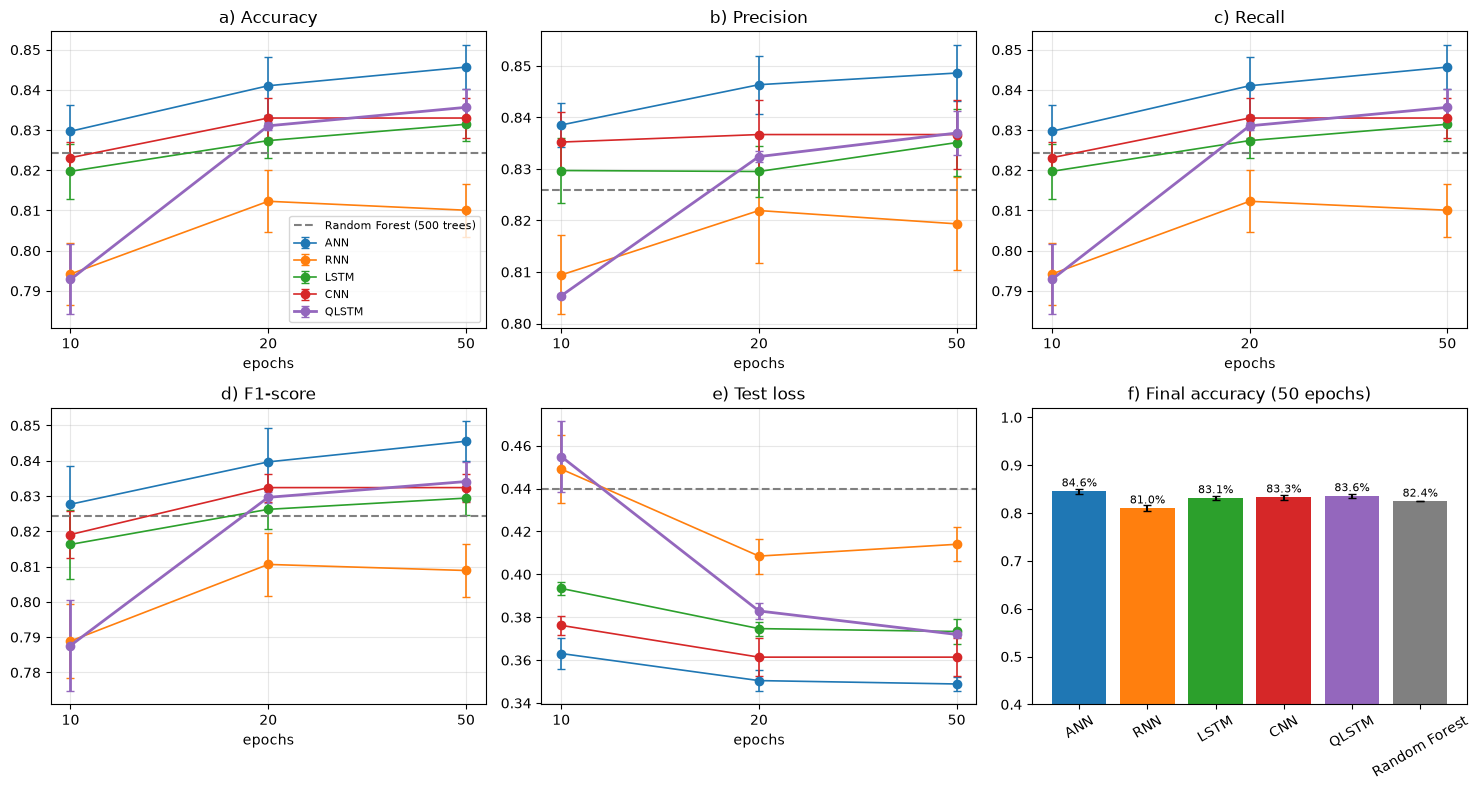

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
x = list(SNAPSHOTS)
names = ["ANN", "RNN", "LSTM", "CNN", "QLSTM"]
for ax, (key, title) in zip(axes.ravel(), [("accuracy", "a) Accuracy"), ("precision", "b) Precision"), ("recall", "c) Recall"),
                                         ("f1", "d) F1-score"), ("loss", "e) Test loss")]):
    for n in names:
        m = [agg(n, s)[key][0] for s in x]; sd = [agg(n, s)[key][1] for s in x]
        ax.errorbar(range(len(x)), m, yerr=sd, marker="o", capsize=3, label=n, lw=2 if n == "QLSTM" else 1.2)
    ax.axhline(rf_rows[0][key], color="gray", ls="--", label=f"Random Forest ({RF_TREES[0]} trees)")
    ax.set_xticks(range(len(x))); ax.set_xticklabels(x); ax.set_xlabel("epochs"); ax.set_title(title); ax.grid(alpha=.3)
axes[0, 0].legend(fontsize=8)
final = {n: agg(n, SNAPSHOTS[-1])["accuracy"] for n in names}
final["Random Forest"] = (rf_rows[0]["accuracy"], 0.0)
ax = axes[1, 2]
bars = ax.bar(list(final), [v[0] for v in final.values()], yerr=[v[1] for v in final.values()], capsize=3,
              color=["C0", "C1", "C2", "C3", "C4", "gray"])
for b, v in zip(bars, final.values()): ax.text(b.get_x() + b.get_width() / 2, v[0] + .01, f"{100*v[0]:.1f}%", ha="center", fontsize=8)
ax.set_ylim(0.4, 1.02); ax.set_title(f"f) Final accuracy ({SNAPSHOTS[-1]} epochs)"); ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout(); plt.show()

### Learning curves (train and validation loss, one seed)

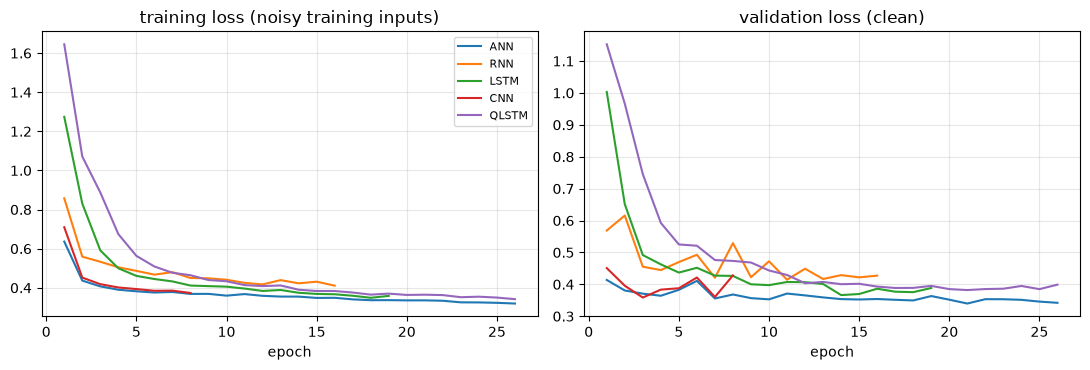

{'ANN': 26, 'RNN': 16, 'LSTM': 19, 'CNN': 8, 'QLSTM': 26} <- epoch at which early stopping fired (None = never)


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for n in names:
    r = next(r for r in results if r["label"] == n)
    h = np.array(r["hist"])
    ax[0].plot(h[:, 0], h[:, 1], label=n); ax[1].plot(h[:, 0], h[:, 2], label=n)
ax[0].set_title("training loss (noisy training inputs)"); ax[1].set_title("validation loss (clean)")
for a in ax: a.set_xlabel("epoch"); a.grid(alpha=.3)
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
print({n: next(r for r in results if r['label'] == n)['stopped_at'] for n in names}, "<- epoch at which early stopping fired (None = never)")

## 12. Confusion matrices (Figure 4 of the paper)

Rows are the true class, columns the predicted class, for the first seed at the last snapshot. Class order is the paper's: 0 Combined, 1 Detector blinding, 2 Intercept-and-resend, 3 Normal, 4 PNS, 5 RNG, 6 Trojan horse, 7 Wavelength-dependent Trojan horse.

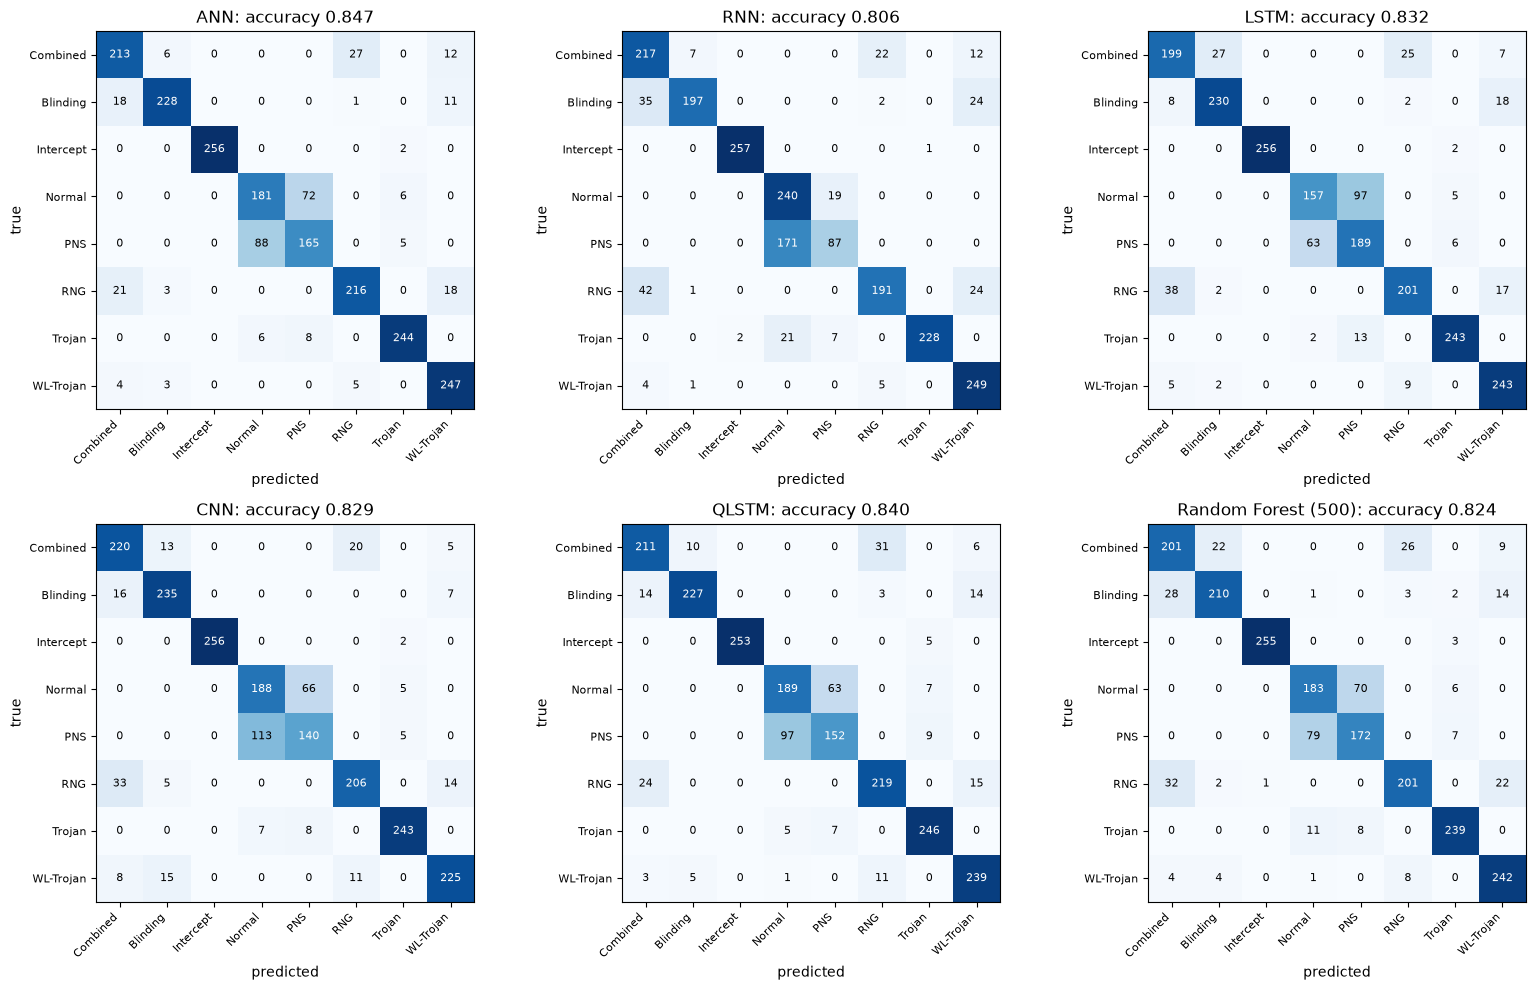

QLSTM: class pairs with most mutual confusion -> [('Normal', 'PNS', 160), ('Combined', 'RNG', 55), ('RNG', 'WL-Trojan', 26)]
per-class F1 of QLSTM: {'Combined': np.float64(0.83), 'Blinding': np.float64(0.91), 'Intercept': np.float64(0.99), 'Normal': np.float64(0.69), 'PNS': np.float64(0.63), 'RNG': np.float64(0.84), 'Trojan': np.float64(0.94), 'WL-Trojan': np.float64(0.9)}


In [22]:
def first(label): return next(r for r in results if r["label"] == label)["snaps"][SNAPSHOTS[-1]]["pred"]
panels = [("ANN", first("ANN")), ("RNN", first("RNN")), ("LSTM", first("LSTM")), ("CNN", first("CNN")),
          ("QLSTM", first("QLSTM")), (f"Random Forest ({RF_TREES[0]})", rf_rows[0]["pred"])]
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for ax, (n, p) in zip(axes.ravel(), panels):
    cm = confusion_matrix(y_te, p, labels=range(8))
    ax.imshow(cm, cmap="Blues")
    for i in range(8):
        for j in range(8):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks(range(8)); ax.set_yticks(range(8)); ax.set_xticklabels(SHORT, rotation=45, ha="right", fontsize=8); ax.set_yticklabels(SHORT, fontsize=8)
    ax.set_title(f"{n}: accuracy {accuracy_score(y_te, p):.3f}"); ax.set_xlabel("predicted"); ax.set_ylabel("true")
plt.tight_layout(); plt.show()

cm_q = confusion_matrix(y_te, first("QLSTM"), labels=range(8)).astype(float)
off = cm_q.copy(); np.fill_diagonal(off, 0)
pairs = sorted([(off[i, j] + off[j, i], SHORT[i], SHORT[j]) for i in range(8) for j in range(i + 1, 8)], reverse=True)[:3]
print("QLSTM: class pairs with most mutual confusion ->", [(a, b, int(n)) for n, a, b in pairs])
print("per-class F1 of QLSTM:", dict(zip(SHORT, np.round(f1_score(y_te, first('QLSTM'), average=None, labels=range(8)), 2))))

### Attack / no-attack view with the paper's TP / TN / FP / FN definitions

Equations (12) to (15) of the paper define accuracy, precision, recall and F1 on "attack" against "normal". Collapsing the 8 classes this way answers the question an operator asks first: is *something* wrong with this session?

In [23]:
def binary_view(pred):
    t = (y_te != CLASS_ID["normal"]); p = (pred != CLASS_ID["normal"])
    tp, tn, fp, fn = (t & p).sum(), (~t & ~p).sum(), (~t & p).sum(), (t & ~p).sum()
    return dict(accuracy=(tp + tn) / len(t), precision=tp / max(tp + fp, 1), recall=tp / max(tp + fn, 1),
                f1=2 * tp / max(2 * tp + fp + fn, 1), false_alarm_rate=fp / max(fp + tn, 1))
bin_tab = pd.DataFrame({n: binary_view(p) for n, p in panels}).T.round(3)
print(bin_tab.to_string())

                     accuracy  precision  recall     f1  false_alarm_rate
ANN                     0.917      0.956   0.948  0.952             0.301
RNN                     0.898      0.988   0.894  0.939             0.073
LSTM                    0.919      0.945   0.964  0.954             0.394
CNN                     0.908      0.960   0.934  0.946             0.274
QLSTM                   0.916      0.961   0.943  0.952             0.270
Random Forest (500)     0.919      0.958   0.949  0.953             0.293


## 13. Resources: Table IX of the paper, recomputed

Parameters, measured wall-clock time per epoch (training only), total training time over the epochs actually run, inference time per sample. The paper's times were measured on an A100 GPU; ours on this machine's CPU with a simulated quantum circuit, so only the **ordering** is comparable.

In [24]:
res_rows = []
for n in names:
    rs = [r for r in results if r["label"] == n]
    model = {"ANN": ANN(), "RNN": RNNNet(), "LSTM": LSTMNet(), "CNN": CNNNet(), "QLSTM": q_model}[n]
    res_rows.append(dict(Model=n, Params=n_params(model), sec_per_epoch=np.mean([r["sec_per_epoch"] for r in rs]),
                         train_sec=np.mean([r["total_sec"] for r in rs]), infer_ms_per_sample=np.mean([r["infer_ms"] for r in rs])))
res_rows.append(dict(Model="Random Forest", Params=rf_rows[0]["nodes"], sec_per_epoch=np.nan,
                     train_sec=rf_rows[0]["sec"], infer_ms_per_sample=np.nan))
table9 = pd.DataFrame(res_rows)
print(table9.round(4).to_string(index=False))

        Model  Params  sec_per_epoch  train_sec  infer_ms_per_sample
          ANN   14440         0.8651    17.0606               0.0027
          RNN   10280         1.8564    37.9757               0.0263
         LSTM   42008         1.5248    30.4444               0.0250
          CNN   20384         1.6992    22.1885               0.0133
        QLSTM    6335       124.6330  3294.4833               2.2693
Random Forest 1008660            NaN     5.6977                  NaN


## 14. Side by side with the paper, claim by claim

Rule for the verdicts: a number is **reproduced** if it lies within 2 accuracy points (0.02 on F1 or precision) of the paper's value; otherwise **not reached** (ours lower) or **exceeded** (ours higher), with the gap. A claim about an ordering or a trend is **reproduced** if the ordering holds in our runs. In `FAST_MODE` the snapshot epochs are 3, 6, 12 instead of 10, 20, 50, so numerical comparisons there are indicative only.

Keep in mind what this comparison *can* test. The authors' data are not available, so we compare the paper's model **on a regenerated dataset of the same kind** against the paper's numbers on its own data. How hard the task is depends on the attack parameters, which the paper does not give (see the table in section 1). A different accuracy level can therefore come from the data and not from the model. Rankings and trends are more transferable than absolute accuracies.

In [25]:
def verdict_num(paper, ours, tol=0.02):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    return ("exceeded" if d > 0 else "not reached") + f" ({100*d:+.1f} pts)"

A = lambda n, s: agg(n, s)
ep10, ep20, ep50 = SNAPSHOTS
rows = []
def add(claim, paper, ours, verdict): rows.append(dict(Claim=claim, Paper=paper, Notebook=ours, Verdict=verdict))

for s, pe, pv in [(ep10, 10, 0.883), (ep20, 20, 0.938), (ep50, 50, 0.947)]:
    o = A("QLSTM", s)["accuracy"][0]
    add(f"C1 QLSTM accuracy @{pe} ep (notebook epoch {s})", f"{100*pv:.1f}%", f"{100*o:.1f}%", verdict_num(pv, o))
o = A("QLSTM", ep50)
add("C1 QLSTM precision @50", "95.1%", f"{100*o['precision'][0]:.1f}%", verdict_num(0.951, o["precision"][0]))
add("C1 QLSTM F1 @50", "94.7%", f"{100*o['f1'][0]:.1f}%", verdict_num(0.947, o["f1"][0]))
add("C1 QLSTM test loss @50", "0.189", f"{o['loss'][0]:.3f}", "reproduced" if abs(o["loss"][0] - 0.189) <= 0.05 else ("lower than paper" if o["loss"][0] < 0.189 else "higher than paper"))

for n, pv in [("ANN", 0.923), ("RNN", 0.760), ("LSTM", 0.851), ("CNN", 0.849)]:
    o = A(n, ep50)["accuracy"][0]
    add(f"C2 {n} accuracy @50", f"{100*pv:.1f}%", f"{100*o:.1f}%", verdict_num(pv, o))
add("C4 Random Forest accuracy (500 trees)", "82.6%", f"{100*rf_rows[0]['accuracy']:.1f}%", verdict_num(0.826, rf_rows[0]["accuracy"]))

accs50 = {n: A(n, ep50)["accuracy"][0] for n in names}; accs50["Random Forest"] = rf_rows[0]["accuracy"]
best = max(accs50, key=accs50.get)
add("C2 QLSTM is the most accurate model @50", "yes, 94.7% vs next best ANN 92.3%",
    "; ".join(f"{k} {100*v:.1f}" for k, v in sorted(accs50.items(), key=lambda kv: -kv[1])),
    "reproduced" if best == "QLSTM" else f"not reached (best: {best})")
gap = accs50["QLSTM"] - max(v for k, v in accs50.items() if k != "QLSTM")
add("C2 margin of QLSTM over the best baseline", "+2.4 pts (over ANN)", f"{100*gap:+.1f} pts", "reproduced" if abs(gap - 0.024) <= 0.02 else ("exceeded" if gap > 0.024 else "not reached"))

lstm_curve = [A("LSTM", s)["accuracy"][0] for s in SNAPSHOTS]; cnn_curve = [A("CNN", s)["accuracy"][0] for s in SNAPSHOTS]; q_curve = [A("QLSTM", s)["accuracy"][0] for s in SNAPSHOTS]
add("C3 LSTM accuracy drops at the last snapshot", "85.8 / 88.2 / 85.1", " / ".join(f"{100*v:.1f}" for v in lstm_curve),
    "reproduced" if lstm_curve[-1] < max(lstm_curve) - 0.005 else "not reached (no drop)")
add("C3 CNN accuracy degrades with more epochs", "86.8 / 86.5 / 84.9", " / ".join(f"{100*v:.1f}" for v in cnn_curve),
    "reproduced" if cnn_curve[-1] < cnn_curve[0] - 0.005 else "not reached (no degradation)")
add("C3 QLSTM keeps improving with epochs", "88.3 / 93.8 / 94.7", " / ".join(f"{100*v:.1f}" for v in q_curve),
    "reproduced" if q_curve[0] <= q_curve[1] + 0.005 and q_curve[1] <= q_curve[2] + 0.005 else "not reached")

pq = n_params(q_model); pl = n_params(LSTMNet())
add("C5 QLSTM has fewer parameters than the LSTM baseline", "3.9e3 (+72 quantum) vs 4.3e4", f"{pq:,} total ({n_q} quantum) vs {pl:,}", "reproduced" if pq < pl else "not reached")
t_by = {r["Model"]: r["sec_per_epoch"] for r in res_rows if r["Model"] != "Random Forest"}
add("C5 QLSTM is the slowest model per epoch", "0.41 s vs 0.30 s (LSTM)", f"{t_by['QLSTM']:.2f} s vs {t_by['LSTM']:.2f} s (LSTM); simulated quantum circuit on CPU", "reproduced" if t_by["QLSTM"] == max(t_by.values()) else "not reached")
add("C6 largest QLSTM confusion involves Normal and PNS", "Normal <-> PNS", f"{pairs[0][1]} <-> {pairs[0][2]} ({int(pairs[0][0])} sessions)",
    "reproduced" if {pairs[0][1], pairs[0][2]} == {"Normal", "PNS"} else "not reached")
add("Dataset fidelity to Table VI (entropy = H2(QBER))", "exact relation", "exact by construction", "reproduced")
add("Absolute QKD accuracy on the authors' data", "94.7%", "authors' dataset unavailable", "cannot be checked")
add("Hardware / GPU timings of Table IX", "A100, 20.5 s for 50 epochs", "CPU simulation, see table", "cannot be checked")

comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 90)
print(comparison.to_string(index=False))
print("\nverdict counts:", comparison["Verdict"].str.split(" ").str[0].value_counts().to_dict())
print(f"seed-to-seed spread at the last snapshot (accuracy std, points): "
      + ", ".join(f"{n} {100*A(n, ep50)['accuracy'][1]:.2f}" for n in names)
      + f" | QLSTM minus ANN: {100*(accs50['QLSTM'] - accs50['ANN']):+.2f} points")
print("QLSTM runs stopped early at epochs:", [r["stopped_at"] for r in results if r["label"] == "QLSTM"], "(None = ran to the end; later snapshots then use the best-validation weights)")

                                               Claim                             Paper                                                                Notebook                      Verdict
        C1 QLSTM accuracy @10 ep (notebook epoch 10)                             88.3%                                                                   79.3%       not reached (-9.0 pts)
        C1 QLSTM accuracy @20 ep (notebook epoch 20)                             93.8%                                                                   83.1%      not reached (-10.7 pts)
        C1 QLSTM accuracy @50 ep (notebook epoch 50)                             94.7%                                                                   83.6%      not reached (-11.1 pts)
                              C1 QLSTM precision @50                             95.1%                                                                   83.7%      not reached (-11.4 pts)
                                     C1 QLSTM F1 @50        

## 15. Reading the paper critically

* **The data are the experiment.** The dataset is the authors' own simulation, "available on request". The sentence "QLSTM reaches 94.7 %" is a statement about *their* simulator and parameters. Every attack strength (how often Eve injects, how noisy her measurements are, how long the detectors stay blinded) is a free parameter that changes how separable the classes are. We regenerated the data from the algorithms and had to choose all of those numbers. Whatever absolute accuracy you obtain, it says more about our parameter choices than about QLSTM. The rankings of the models are the more transferable result.
* **Internal inconsistencies.** Algorithm 2 sets `Ntrans = 50` pulses, yet sifted keys have 142 to 454 bits (Table VI); the model has "4 logits" but all results use 8 classes; the learning rate is 5e-4 in the text and 0.005 in Table VII; the abstract says "94.7.0 %"; "three architectures" lists five; the Normal class is said to have QBER near zero while the example row has 5.5 %; Table VI shows 9 feature columns but the text says 11 features with two dropped.
* **A sequence model on a bag of features.** The 9 features are fed as 9 *time steps*. They are not a time series: their order is arbitrary (the paper never says how it was fixed). Recurrence over feature order gives no physical benefit, and an LSTM, a CNN and a QLSTM are here just differently structured function approximators over 9 numbers. A shuffled-order experiment (Exercise 2) tests this.
* **Fair comparison.** The text says the QLSTM was compared "under identical conditions", but the classical models' sizes and the Random Forest settings are not given, nothing is said about a validation set (only "test loss" is reported; early stopping on a test loss would leak), and each number comes from a single run with no spread. In our runs (five seeds for each classical network, two for the QLSTM) the seed-to-seed standard deviation of the accuracy is 0.4 to 0.9 points, and ANN, QLSTM, CNN, LSTM and Random Forest all end within about two points of each other (82.4 to 84.6 %), the same size as that spread. On this data a ranking among them is not established, and the 2.4 to 19 point margins of the paper's Table VIII do not appear.
* **Random Forest as a baseline.** A Random Forest on 9 tabular features is usually a strong baseline. On our regenerated data it reaches 82.4 to 82.7 % for 500 to 10,000 trees, the same as the paper's 82.6 % (and more trees do not help, as in the paper). This agreement is a coincidence of our untuned parameter choices and the timing bookkeeping of section 6, not a fitted result, but it shows that the task has a similar difficulty. The paper's picture of the forest as hitting "a ceiling" that only quantum-enhanced architectures can pass is not supported here: a plain ANN, a small CNN and the QLSTM pass it by one to two points, which is about the seed spread.
* **Timing claims.** Table IX reports 20.5 s for 50 QLSTM epochs. Our exact simulation of the 9-qubit circuits (four gates at each of the 9 time steps) needs one to two minutes per epoch on a CPU, about two orders of magnitude more than the LSTM, and PennyLane's own simulator is another factor of about 20 slower than our PyTorch twin. Only the ordering (QLSTM slowest) is comparable with the paper. No quantum hardware is used or needed, so whatever the QLSTM achieves is a statement about a small parametrised model on a classical simulator, not about quantum hardware.
* **Training length.** The paper trains "50 epochs" and says QLSTM keeps improving. With early stopping on a validation set (patience 5) our QLSTM runs stopped at epochs 26 and 27, so the epoch-50 row is the best-validation model of epoch about 21 to 22 and the 20-to-50 gain (0.5 points) is not a measure of further learning. The paper does not say whether its 50-epoch rows were stopped early.
* **A bookkeeping artifact in the data.** Table VI shows that the last four scenarios were timed over all pulses and the first four over detected photons only. With both timing columns among the model inputs the two groups are separable by the ratio of those columns alone. Removing the artifact in our regeneration lowers the Random Forest from 82.7 % to 67.3 %. The remaining errors of every model, including the QLSTM, sit mostly between Normal and PNS, as the paper also found. We cannot tell whether the authors' complete file has the artifact in all rows (only the eight printed rows show it), but if it does, part of the 94.7 % is a property of the dataset generation and not of the physics or the model.
* **What the dataset can and cannot teach about real QKD security.** The authors say it themselves: attacks are simplified variants (no loss compensation in PNS, no calibrated Trojan-horse power). The difficult real attacks (loss-compensated PNS, perfectly synchronised blinding) are designed to leave no statistical trace, which is precisely what this detector relies on.

## 16. Exercises

1. **Attack strength.** In the simulator, halve the intercept fraction range of the intercept-and-resend attack and the injection probabilities of the Trojan-horse attacks. How do the accuracies of all models and the Random Forest change? Which class pairs become confusable first?
2. **Does the order of the features matter?** Permute the 9 feature columns randomly (the same permutation for train and test) and retrain LSTM and QLSTM. If the accuracy does not change, the recurrent structure is not extracting temporal information.
3. **Seeds and error bars.** Increase `QLSTM_SEEDS` to five seeds and `CLASSICAL_SEEDS` to ten. Is the margin of QLSTM over the ANN larger than the standard deviation?
4. **Circuit design.** Change `n_qlayers` to 2 or 3, or replace Strongly Entangling Layers by Basic Entangler Layers (the reference implementation). Use `QUANTUM_BACKEND = "pennylane"` for one step to confirm your edit of the fast twin still matches PennyLane.
5. **Operational view.** Using the binary table in section 12, choose a decision threshold on the Normal-class probability so that the false alarm rate is below 1 %. What recall do you keep for each attack type?